In [1]:
import arviz as az
import arviz_plots as azp
from arviz_base import load_arviz_data
azp.style.use("arviz-variat")
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, Predictive

/Users/signer/miniforge3/envs/aiDprob/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Generate fake data

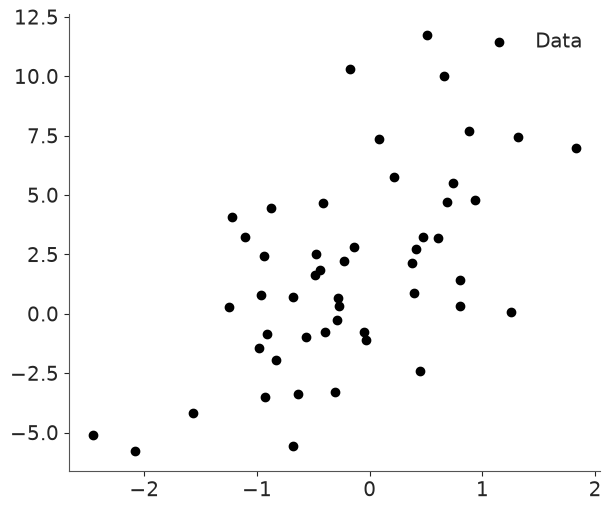

In [2]:
key = jax.random.PRNGKey(42)
n = 50

true_intercept = 2.0
true_slope = 3.0
true_sigma = 3.0

key, sub_key = jax.random.split(key)
x = jax.random.normal(sub_key, shape=(n,))
key, sub_key = jax.random.split(key)
y = (
    true_slope * x
    + true_intercept
    + true_sigma * jax.random.normal(sub_key, shape=(n,))
)

plt.figure()
plt.scatter(x, y, label="Data", color="k")
plt.legend()
plt.show()

## Define model

In [3]:
def model(x: jax.Array, y: jax.Array | None = None) -> None:
    intercept = numpyro.sample("intercept", dist.Normal(0, 10))

    slope = numpyro.sample("slope", dist.Normal(0, 10))

    sigma = numpyro.sample("sigma", dist.HalfNormal(5))

    mu = intercept + slope * x

    with numpyro.plate("data", len(x)):
        numpyro.sample("obs", dist.Normal(mu, sigma), obs=y)

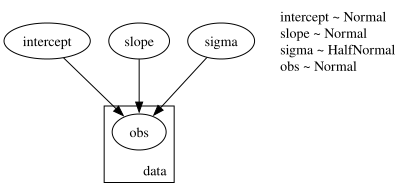

In [4]:
numpyro.render_model(model, model_kwargs={"x": x}, render_distributions=True)

## Doing inference

In [5]:
kernel = NUTS(model)
mcmc = MCMC(kernel, num_warmup=500, num_samples=10000)
key, sub_key = jax.random.split(key)
mcmc.run(sub_key, x=x, y=y)
mcmc.print_summary()

sample: 100%|██████████| 10500/10500 [00:01<00:00, 6123.30it/s, 3 steps of size 7.65e-01. acc. prob=0.89]


                 mean       std    median      5.0%     95.0%     n_eff     r_hat
  intercept      2.24      0.50      2.23      1.40      3.02   7174.07      1.00
      sigma      3.43      0.36      3.40      2.86      4.01  10268.47      1.00
      slope      2.69      0.57      2.69      1.80      3.67   9799.26      1.00

Number of divergences: 0


In [6]:
posterior_samples = mcmc.get_samples()
idata = az.from_numpyro(mcmc)

<Figure size 600x500 with 0 Axes>

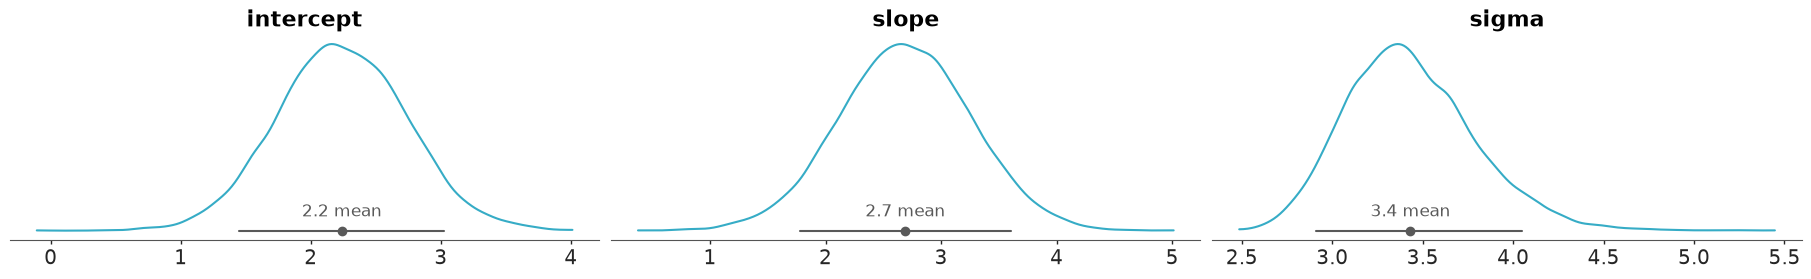

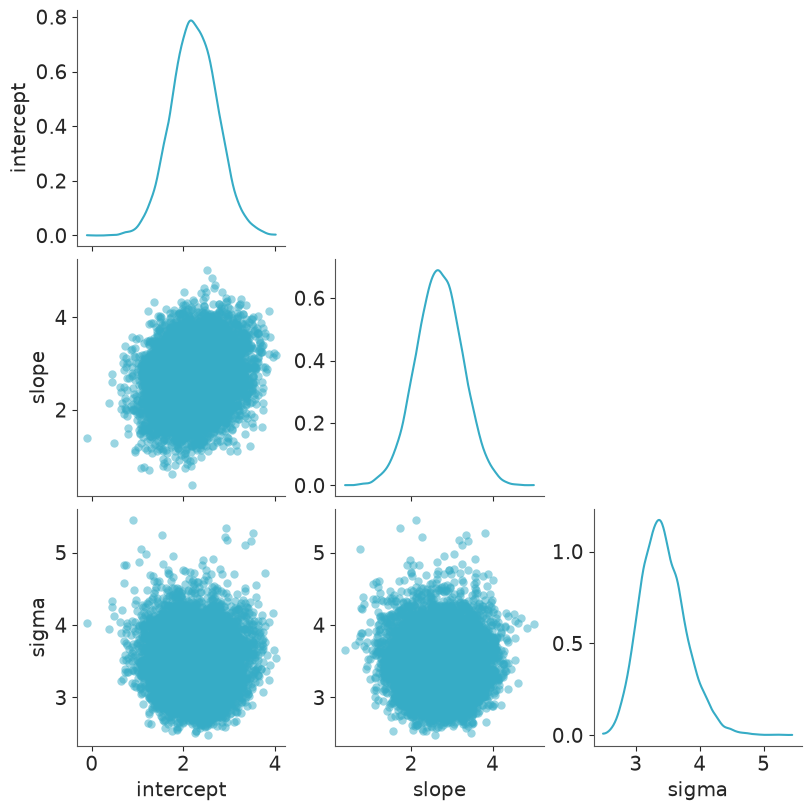

In [7]:
plt.figure()
az.plot_dist(idata, var_names=["intercept", "slope", "sigma"])
azp.plot_pair(idata, var_names=["intercept", "slope", "sigma"])
plt.gcf().set_size_inches(8, 8)
plt.show()

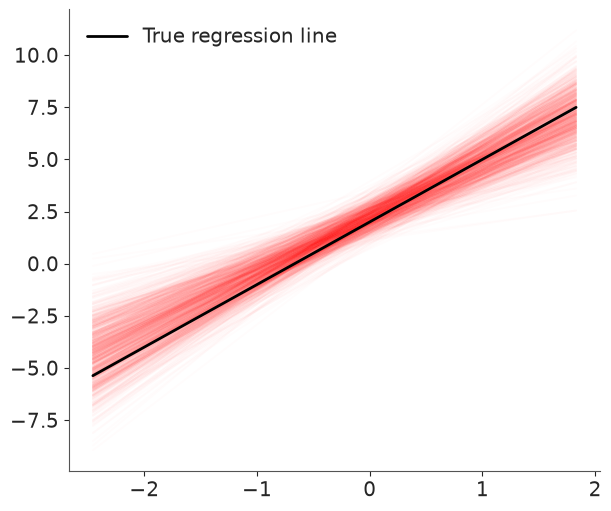

In [8]:
x_plot = jnp.linspace(x.min(), x.max(), 100)
y_true = true_intercept + true_slope * x_plot
n_lines = 1000

key, subkey = jax.random.split(key)
idx = jax.random.choice(
    subkey, len(posterior_samples["slope"]), shape=(n_lines,), replace=False
)

plt.figure()
for i in idx:
    intercept_i = posterior_samples["intercept"][i]
    slope_i = posterior_samples["slope"][i]
    y_line = intercept_i + slope_i * x_plot
    plt.plot(x_plot, y_line, alpha=0.01, color="red")
plt.plot(x_plot, y_true, linewidth=2, label="True regression line", color="black")
plt.legend()
plt.show()

## Sample new points

In [9]:
key, sub_key = jax.random.split(key)
posterior_predictive = Predictive(model, posterior_samples=posterior_samples)
predictive_samples = posterior_predictive(sub_key, x=x)
y_new = predictive_samples["obs"][0, :]

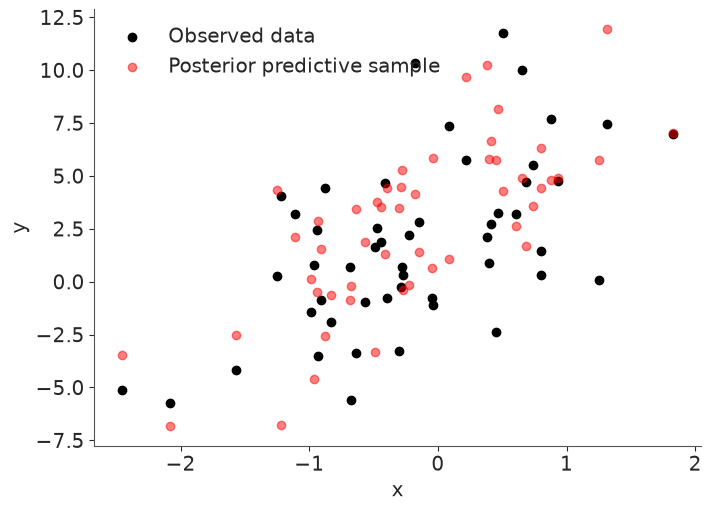

In [10]:
plt.figure(figsize=(7, 5))

plt.scatter(x, y, color="black", label="Observed data")
plt.scatter(x, y_new, color="red", alpha=0.5, label="Posterior predictive sample")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

## Diagnostics - Trace plots

<Figure size 600x500 with 0 Axes>

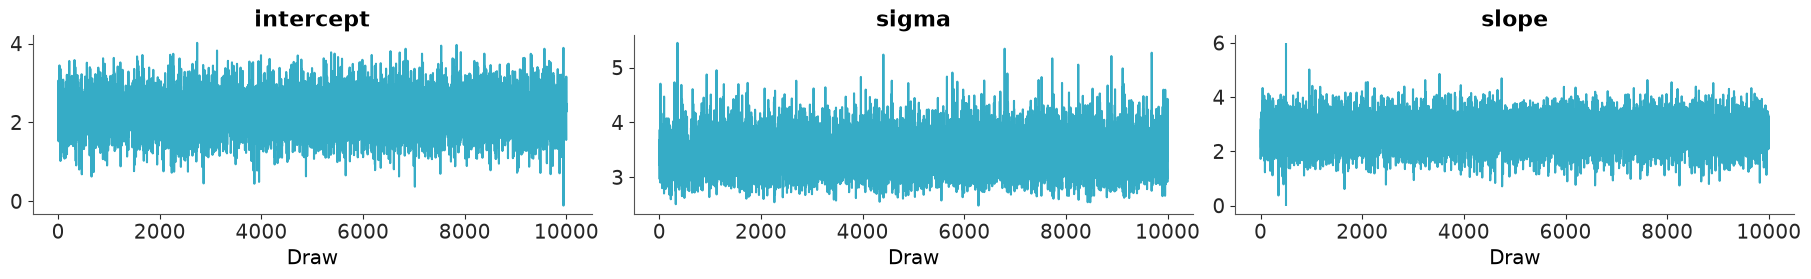

In [ ]:

plt.figure()
azp.plot_trace(idata, )
plt.show()

## Running analysis with more chains

In [12]:
kernel = NUTS(model)
mcmc = MCMC(kernel, num_warmup=500, num_samples=10000, num_chains=4)
key, sub_key = jax.random.split(key)
mcmc.run(sub_key, x=x, y=y)
mcmc.print_summary()

/var/folders/s2/mbvmlfps7636zy4zhhmlsqh00000gn/T/ipykernel_11118/1064577410.py:2: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(kernel, num_warmup=500, num_samples=10000, num_chains=4)
sample: 100%|██████████| 10500/10500 [00:01<00:00, 8221.44it/s, 3 steps of size 7.64e-01. acc. prob=0.91]



                 mean       std    median      5.0%     95.0%     n_eff     r_hat
  intercept      2.25      0.50      2.25      1.42      3.04  34064.03      1.00
      sigma      3.43      0.36      3.40      2.84      4.00  29228.01      1.00
      slope      2.69      0.57      2.69      1.72      3.59  33200.40      1.00

Number of divergences: 0


In [13]:
idata = az.from_numpyro(mcmc)

<Figure size 600x500 with 0 Axes>

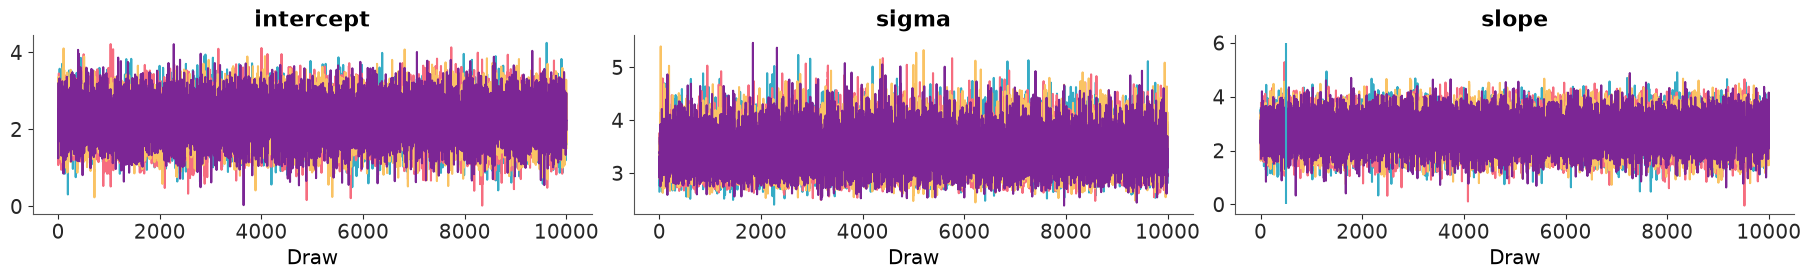

In [ ]:
plt.figure()
azp.plot_trace(idata)
plt.show()

## Diagnostics - Effective sample size

<Figure size 600x500 with 0 Axes>

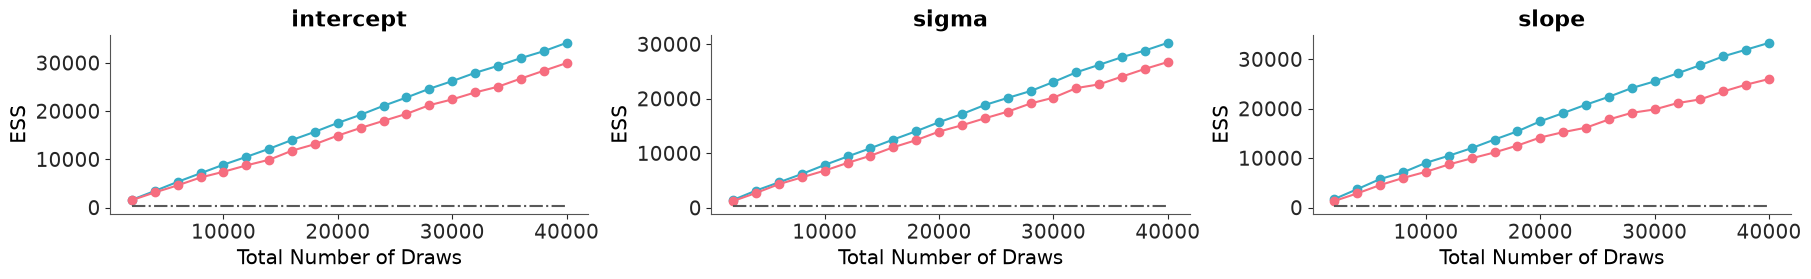

In [ ]:
plt.figure()
azp.plot_ess_evolution(idata)
plt.show()
# Shows mean and deviation of ESS across the four chains

<Figure size 600x500 with 0 Axes>

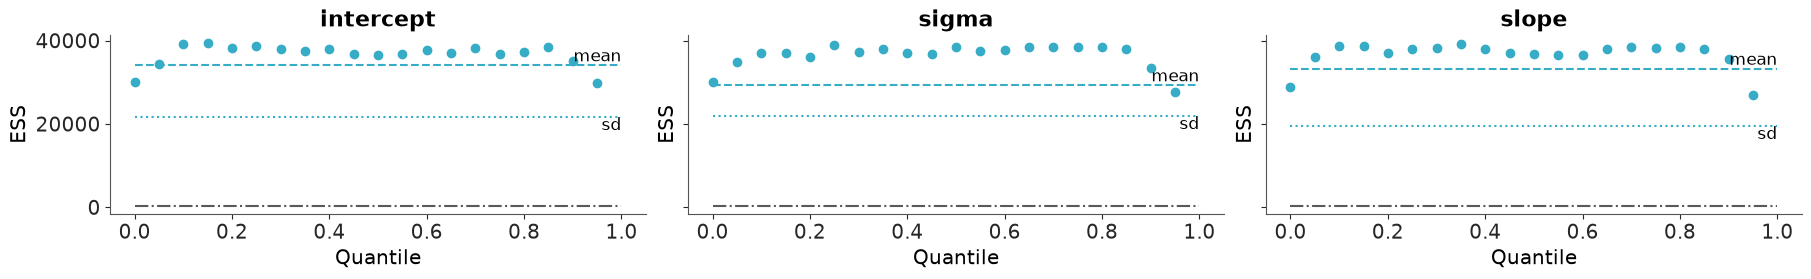

In [ ]:
plt.figure()
azp.plot_ess(idata, extra_methods=True)
plt.show()
# Shows mean and deviation of ESS across all quantiles. Stable and efficient ESS across all quantiles indicate good mixing and convergence of the chains.

## Diagnostics - Monte Carlo Standard Error

<Figure size 600x500 with 0 Axes>

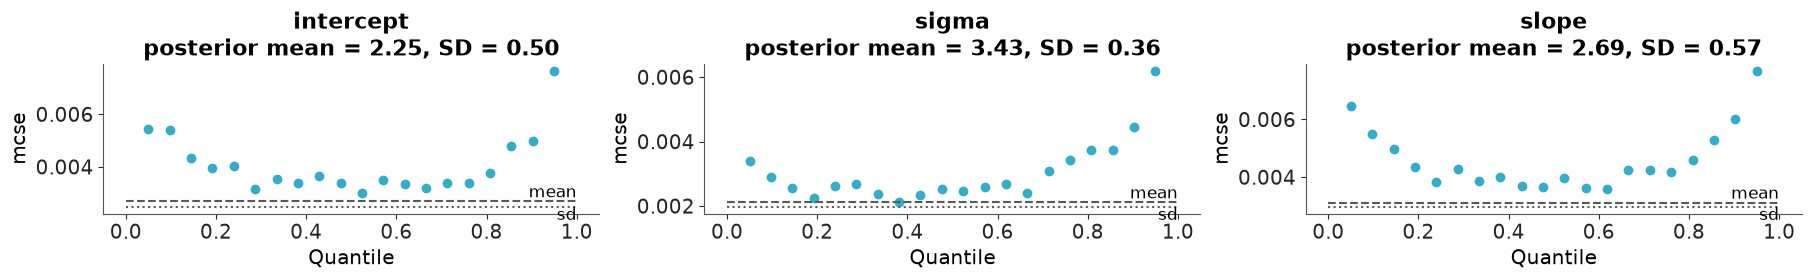

In [26]:
plt.figure()
azp.plot_mcse(idata, extra_methods=True)
for ax in plt.gcf().axes:
    var_name = ax.get_title()
    samples = idata.posterior[var_name]

    posterior_mean = samples.mean().item()
    posterior_sd = samples.std().item()

    ax.set_title(
        f"{var_name}\nposterior mean = {posterior_mean:.2f}, SD = {posterior_sd:.2f}"
    )

plt.show()
# The horizontal dashed lines are reference MCSEs for the parameter’s posterior mean and standard deviation.